# Single-Stock Risk Report

A **parameterized** report for one ticker over one date window, built on the validated
`ohlc_hw_cleaned` table from `01_data_cleaning.ipynb`. Run it interactively, or execute it at scale with
papermill (`03_run_all_stocks.py`), which overrides the tagged `parameters` cell below.

**Conventions**

* Returns, volatility, Sharpe and drawdown use **adjusted close** (dividends and splits included).
* Daily returns are **log returns**; annualization uses 252 trading days. A return that would span a
  missing session (per the reference calendar) is left undefined, so every return is a genuine one-day move.
* Values are fractions in calculations and exported results; they are formatted as percentages only for display.

In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "../data/data.db"  # Local working copy of the course database

In [2]:
# Parameters
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/dhruvchopra/dev/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/data/data.db"


In [3]:
import sqlite3
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

TRADING_DAYS = 252
VOL_WINDOW = 20
MA_WINDOW = 50
RISK_FREE_RATE = 0.02
MIN_PRICES = VOL_WINDOW + 1          # 20 returns need at least 21 prices

# One palette for the whole report.
COLORS = {"price": "#1f3b73", "ma": "#f39c12", "up": "#2e8b57", "down": "#c0392b",
          "neutral": "#9e9e9e", "vol": "#6c3483", "dd": "#c0392b"}

## Data loading and validation

In [4]:
def validate_parameters(ticker: str, start_date: str, end_date: str, db_path: str) -> tuple[pd.Timestamp, pd.Timestamp]:
    '''Fail early with a clear message instead of producing an empty or misleading report.'''
    if not isinstance(ticker, str) or not ticker.strip():
        raise ValueError("ticker must be a non-empty string")
    start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
    if start > end:
        raise ValueError(f"start_date {start_date} is after end_date {end_date}")
    if not Path(db_path).exists():
        raise FileNotFoundError(f"Database not found: {Path(db_path).resolve()}")
    return start, end


def load_prices(ticker: str, start_date: str, end_date: str, db_path: str) -> pd.DataFrame:
    '''Cleaned daily rows for one ticker in [start_date, end_date], indexed by date.'''
    query = '''
        SELECT ts, open, high, low, close, adj_close, volume,
               extreme_return_flag, zero_volume_flag, weekend_flag, adj_close_rebuilt
        FROM ohlc_hw_cleaned
        WHERE ticker = ? AND ts BETWEEN ? AND ?
        ORDER BY ts
    '''
    with sqlite3.connect(f"file:{Path(db_path).resolve()}?mode=ro", uri=True) as conn:
        df = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date), parse_dates=["ts"])
    return df.set_index("ts")


def load_expected_sessions(ticker: str, start_date: str, end_date: str, db_path: str) -> pd.DatetimeIndex:
    '''The ticker's expected trading sessions in the window, from the reference calendar (table ohlc).'''
    query = "SELECT DISTINCT ts FROM ohlc WHERE TRIM(ticker) = ? AND ts BETWEEN ? AND ? ORDER BY ts"
    with sqlite3.connect(f"file:{Path(db_path).resolve()}?mode=ro", uri=True) as conn:
        sessions = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date), parse_dates=["ts"])
    return pd.DatetimeIndex(sessions["ts"])


def after_gap_mask(index: pd.DatetimeIndex, sessions: pd.DatetimeIndex) -> pd.Series:
    '''True where the previous retained row is not the previous expected session (a session is missing).

    A log return across such a gap spans several days, so it must not be treated as a one-day return.'''
    position = pd.Series(sessions.get_indexer(index), index=index)
    gap = position.diff().ne(1)
    gap.iloc[0] = False                      # the first row has no previous price in the window anyway
    return gap | position.eq(-1)             # a date missing from the calendar is treated as a gap too


ticker = ticker.strip().upper()
start, end = validate_parameters(ticker, start_date, end_date, db_path)
df = load_prices(ticker, start_date, end_date, db_path)

if len(df) < MIN_PRICES:
    raise ValueError(f"Insufficient history for {ticker} from {start_date} to {end_date}: {len(df)} prices; "
                     f"a {VOL_WINDOW}-day volatility needs at least {MIN_PRICES}.")
assert df.index.is_unique and df.index.is_monotonic_increasing
assert np.isfinite(df["adj_close"]).all() and (df["adj_close"] > 0).all()

first_obs, last_obs = df.index[0], df.index[-1]
sessions = load_expected_sessions(ticker, start_date, end_date, db_path)
df["after_gap"] = after_gap_mask(df.index, sessions)
missing_sessions = sessions[(sessions >= first_obs) & (sessions <= last_obs)].difference(df.index)
print(f"{ticker} from {start_date} to {end_date}: {len(df)} trading days")
print(f"Actual observations: {first_obs.date()} to {last_obs.date()}")
print(f"Expected sessions missing inside the observed range: {len(missing_sessions)}"
      + (f" ({', '.join(str(d.date()) for d in missing_sessions[:5])}{' ...' if len(missing_sessions) > 5 else ''})"
         if len(missing_sessions) else ""))

AAPL from 2024-06-01 to 2024-11-30: 97 trading days
Actual observations: 2024-06-03 to 2024-10-18
Expected sessions missing inside the observed range: 0


In [5]:
coverage_notes = []
if first_obs > start + pd.Timedelta(days=7):
    coverage_notes.append(f"data starts {first_obs.date()}, after the requested start {start_date}")
if last_obs < end - pd.Timedelta(days=7):
    coverage_notes.append(f"data ends {last_obs.date()}, before the requested end {end_date}")
coverage_note = "; ".join(coverage_notes) or "observations cover the requested window"
print("Coverage:", coverage_note)

flag_cols = ["extreme_return_flag", "zero_volume_flag", "weekend_flag", "adj_close_rebuilt"]
print("Data-quality flags in this window:", df[flag_cols].sum().astype(int).to_dict())
display(df.head())
display(df.tail())

Coverage: data ends 2024-10-18, before the requested end 2024-11-30
Data-quality flags in this window: {'extreme_return_flag': 0, 'zero_volume_flag': 0, 'weekend_flag': 0, 'adj_close_rebuilt': 7}


,open,high,low,close,adj_close,volume,extreme_return_flag,zero_volume_flag,weekend_flag,adj_close_rebuilt,after_gap
ts,,,,,,,,,,,
2024-06-03,192.90,194.99,192.52,194.03,193.81,50080539,0,0,0,0,False
2024-06-04,194.64,195.32,193.03,194.35,194.13,47471445,0,0,0,0,False
2024-06-05,195.40,196.90,194.87,195.87,195.64,54156785,0,0,0,0,False
2024-06-06,195.69,196.50,194.17,194.48,194.26,41181753,0,0,0,0,False
2024-06-07,194.65,196.94,194.14,196.89,196.66,53103912,0,0,0,0,False


,open,high,low,close,adj_close,volume,extreme_return_flag,zero_volume_flag,weekend_flag,adj_close_rebuilt,after_gap
ts,,,,,,,,,,,
2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100,0,0,0,0,False
2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400,0,0,0,0,False
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240,0,0,0,0,False
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810,0,0,0,0,False
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281,0,0,0,0,False


## Risk metrics

In [6]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    '''Calculate daily log returns.

    Args:
        prices: Positive, date-sorted adjusted close prices.

    Returns:
        log(P_t / P_{t-1}); the first value is NaN because it has no previous price.
    '''
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = VOL_WINDOW) -> pd.Series:
    '''Calculate annualized rolling volatility.

    Args:
        returns: Daily log returns.
        window: Number of returns in each rolling estimate.

    Returns:
        Sample standard deviation over each full window times sqrt(252). The warm-up period stays
        NaN (not zero): there is no estimate until `window` returns exist.
    '''
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    '''Return per-date drawdown from the running price peak.

    Args:
        prices: Date-sorted adjusted close prices.

    Returns:
        (price - running max) / running max, a value <= 0 that recovers toward 0 after a new peak.
        The maximum drawdown is `drawdown.min()`; the running worst is `drawdown.cummin()`.
    '''
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = RISK_FREE_RATE) -> float:
    '''Calculate annualized Sharpe ratio (course approximation).

    Args:
        returns: Daily log returns (NaN values are ignored).
        risk_free_rate: Annual risk-free rate as a fraction.

    Returns:
        (mean * 252 - rf) / (std * sqrt(252)), or NaN when there are fewer than two returns or the
        standard deviation is zero/undefined.
    '''
    observed = returns.dropna()
    sigma = observed.std()
    if len(observed) < 2 or not np.isfinite(sigma) or np.isclose(sigma, 0):
        return np.nan
    return (observed.mean() * TRADING_DAYS - risk_free_rate) / (sigma * np.sqrt(TRADING_DAYS))


# Quick checks of edge cases on tiny inputs.
_toy = pd.Series([100.0, 110.0, 99.0, 120.0])
assert np.isclose(calculate_returns(_toy).iloc[1], np.log(1.1))
assert np.isclose(calculate_max_drawdown(_toy).min(), 99 / 110 - 1)
assert calculate_max_drawdown(_toy).iloc[-1] == 0           # recovers at a new peak
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.01, 0.01, 0.01])))   # zero volatility
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.01])))               # insufficient returns

In [7]:
# Returns that would span a missing session are left undefined rather than counted as one-day moves.
df["log_return"] = calculate_returns(df["adj_close"]).where(~df["after_gap"])
df["volatility"] = calculate_volatility(df["log_return"])
df["drawdown"] = calculate_max_drawdown(df["adj_close"])
df["ma_50"] = df["adj_close"].rolling(MA_WINDOW).mean()

returns = df["log_return"].dropna()
gap_returns = int(df["after_gap"].sum())
if len(returns) < VOL_WINDOW:
    raise ValueError(f"Insufficient usable returns for {ticker}: {len(returns)} (need {VOL_WINDOW}); "
                     f"{gap_returns} returns were excluded because they span missing sessions.")
print(f"Returns excluded because they span a missing session: {gap_returns}")
mean_vol = df["volatility"].mean()           # mean of the available rolling estimates
sharpe = calculate_sharpe_ratio(returns)
print(f"Log returns: {len(returns)} | rolling-vol estimates: {df['volatility'].notna().sum()} "
      f"| 50-day MA values: {df['ma_50'].notna().sum()}")
print(f"Sharpe ratio: {sharpe:.3f}" if np.isfinite(sharpe) else "Sharpe ratio: N/A")
df[["adj_close", "log_return", "volatility", "drawdown", "ma_50"]].iloc[[0, 1, VOL_WINDOW, -1]]

Returns excluded because they span a missing session: 0
Log returns: 96 | rolling-vol estimates: 77 | 50-day MA values: 48
Sharpe ratio: 1.909


,adj_close,log_return,volatility,drawdown,ma_50
ts,,,,,
2024-06-03,193.81,NaN,NaN,0.0,NaN
2024-06-04,194.13,0.001650,NaN,0.0,NaN
2024-07-02,220.02,0.016128,0.335958,0.0,NaN
2024-10-18,235.00,0.012202,0.209521,0.0,225.5246


## Visualization

* **Price** — segments are coloured by the 20-day volatility on that date: red above the report's mean
  rolling volatility, green at or below it, gray during the warm-up when no estimate exists. This is
  retrospective colouring (the threshold uses the whole window).
* **Drawdown** — layered transparent red fills give a gradient that deepens with the drawdown.

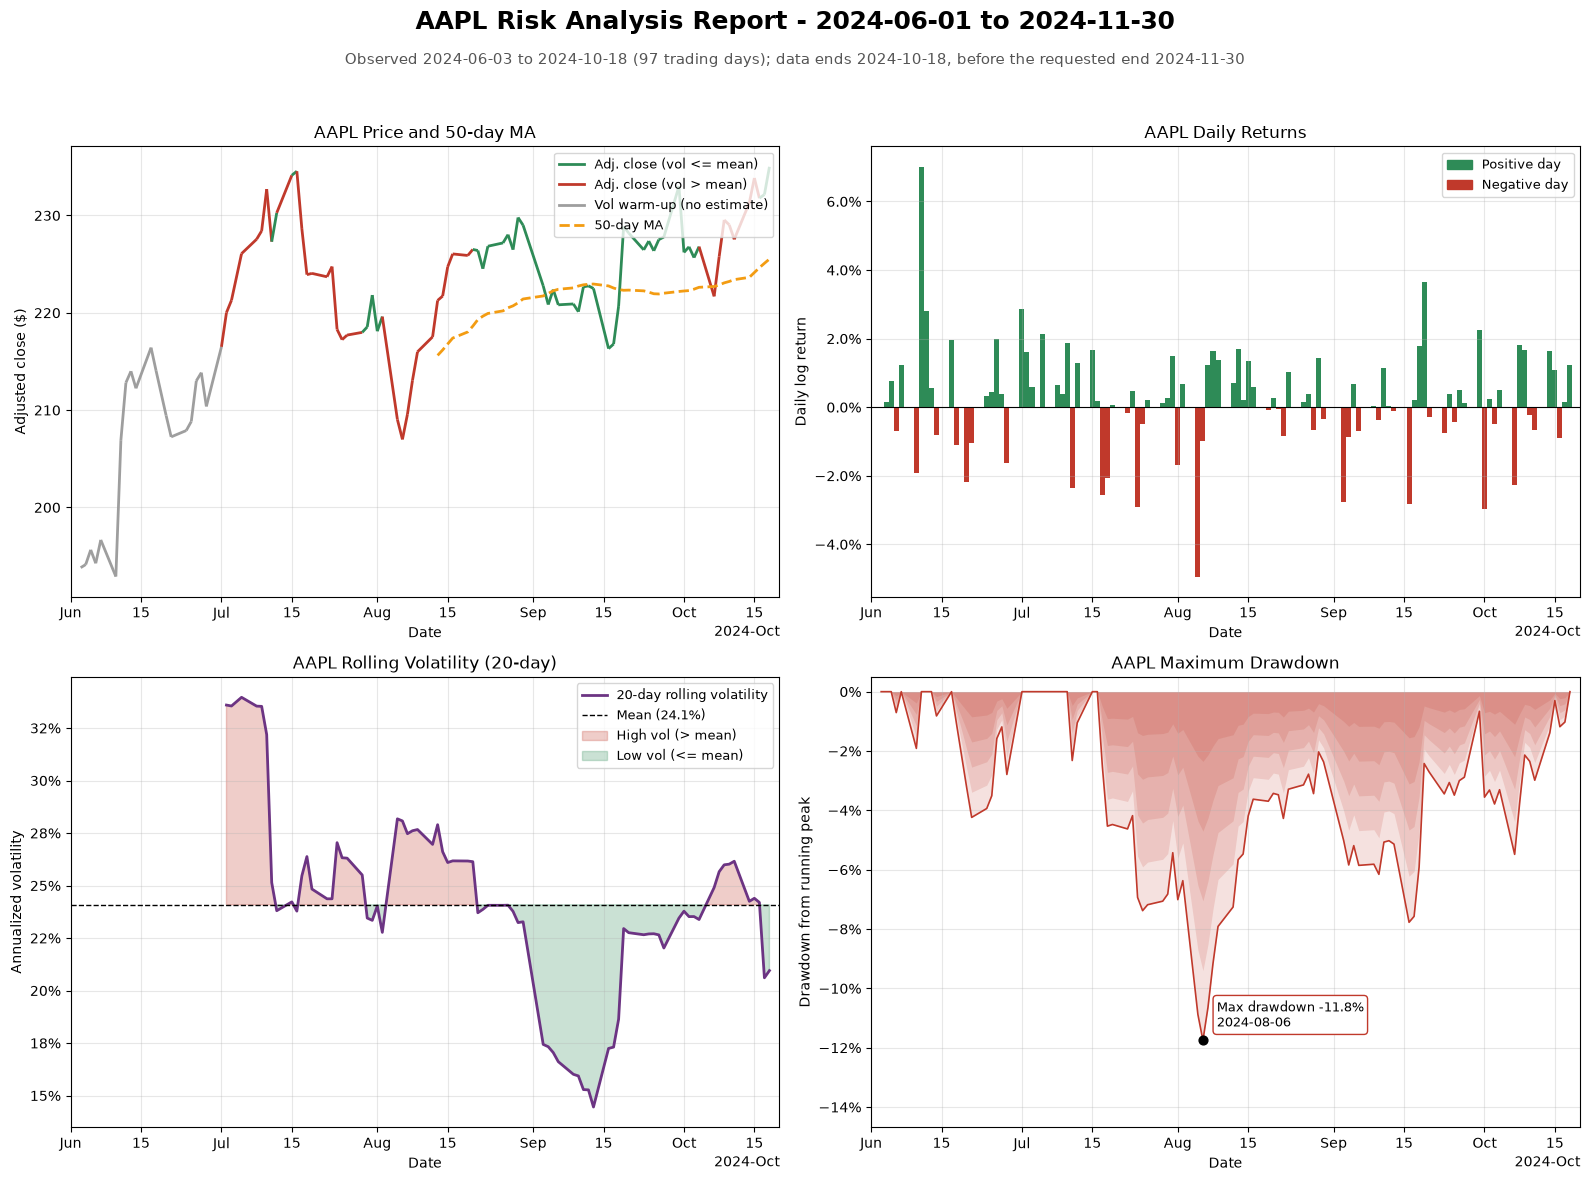

In [8]:
def pct_axis(ax, decimals=0):
    '''Format the y axis of `ax` as percentages of fractional values.'''
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=decimals))


def date_axis(ax):
    '''Use automatic, concise date ticks on the x axis of `ax`.'''
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))


def plot_price(ax):
    '''Top left: adjusted close coloured by volatility regime, plus the 50-day moving average.'''
    x = mdates.date2num(df.index.to_pydatetime())
    points = np.column_stack([x, df["adj_close"].to_numpy()])
    segments = np.stack([points[:-1], points[1:]], axis=1)
    vol = df["volatility"].to_numpy()[1:]      # colour each segment by the vol at its end date
    seg_colors = np.where(np.isnan(vol), COLORS["neutral"],
                          np.where(vol > mean_vol, COLORS["down"], COLORS["up"]))
    ax.add_collection(LineCollection(segments, colors=seg_colors, linewidths=2))
    ax.autoscale_view()
    handles = [Line2D([], [], color=COLORS["up"], lw=2, label="Adj. close (vol <= mean)"),
               Line2D([], [], color=COLORS["down"], lw=2, label="Adj. close (vol > mean)"),
               Line2D([], [], color=COLORS["neutral"], lw=2, label="Vol warm-up (no estimate)")]
    if df["ma_50"].notna().any():
        ax.plot(df.index, df["ma_50"], color=COLORS["ma"], lw=2, ls="--")
        handles.append(Line2D([], [], color=COLORS["ma"], lw=2, ls="--", label="50-day MA"))
    else:
        # Not enough history: say so in the legend instead of drawing a misleading partial average.
        handles.append(Line2D([], [], color="none", label=f"50-day MA unavailable ({len(df)} prices < {MA_WINDOW})"))
    ax.legend(handles=handles, loc="best", fontsize=9)
    ax.set(title=f"{ticker} Price and 50-day MA", xlabel="Date", ylabel="Adjusted close ($)")


def plot_returns(ax):
    '''Top right: daily log returns as green (up) and red (down) bars around a zero line.'''
    r = df["log_return"].dropna()
    ax.bar(r.index, r, width=1.0, color=np.where(r >= 0, COLORS["up"], COLORS["down"]))
    ax.axhline(0, color="black", lw=0.8)
    pct_axis(ax, 1)
    ax.legend(handles=[Patch(color=COLORS["up"], label="Positive day"),
                       Patch(color=COLORS["down"], label="Negative day")], fontsize=9)
    ax.set(title=f"{ticker} Daily Returns", xlabel="Date", ylabel="Daily log return")


def plot_volatility(ax):
    '''Bottom left: 20-day rolling volatility against its mean, with high/low regimes shaded.'''
    vol = df["volatility"]
    ax.plot(vol.index, vol, color=COLORS["vol"], lw=2, label="20-day rolling volatility")
    ax.axhline(mean_vol, color="black", ls="--", lw=1, label=f"Mean ({mean_vol:.1%})")
    ax.fill_between(vol.index, vol, mean_vol, where=vol > mean_vol, interpolate=True,
                    color=COLORS["down"], alpha=0.25, label="High vol (> mean)")
    ax.fill_between(vol.index, vol, mean_vol, where=vol <= mean_vol, interpolate=True,
                    color=COLORS["up"], alpha=0.25, label="Low vol (<= mean)")
    pct_axis(ax)
    ax.legend(fontsize=9)
    ax.set(title=f"{ticker} Rolling Volatility (20-day)", xlabel="Date", ylabel="Annualized volatility")


def plot_drawdown(ax):
    '''Bottom right: per-date drawdown as a red gradient area, with the maximum drawdown marked.'''
    dd = df["drawdown"]
    for depth in np.linspace(0.2, 1.0, 5):          # layered fills -> red/pink gradient
        ax.fill_between(dd.index, dd * depth, 0, color=COLORS["dd"], alpha=0.15, lw=0)
    ax.plot(dd.index, dd, color=COLORS["dd"], lw=1.2)
    trough = dd.idxmin()
    ax.scatter([trough], [dd.min()], color="black", zorder=5, s=40)
    ax.annotate(f"Max drawdown {dd.min():.1%}\n{trough.date()}", xy=(trough, dd.min()),
                xytext=(10, 10), textcoords="offset points", fontsize=9,
                bbox=dict(boxstyle="round", fc="white", ec=COLORS["dd"]))
    ax.set_ylim(min(dd.min() * 1.25, -0.01), 0.005)
    pct_axis(ax)
    ax.set(title=f"{ticker} Maximum Drawdown", xlabel="Date", ylabel="Drawdown from running peak")


fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for plot, ax in zip([plot_price, plot_returns, plot_volatility, plot_drawdown], axes.flat):
    plot(ax)
    date_axis(ax)
    ax.set_xlim(first_obs - pd.Timedelta(days=2), last_obs + pd.Timedelta(days=2))   # same window on every panel
    ax.grid(alpha=0.3)
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18, fontweight="bold")
fig.text(0.5, 0.935, f"Observed {first_obs.date()} to {last_obs.date()} ({len(df)} trading days); {coverage_note}",
         ha="center", fontsize=11, color="#555555")
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## Summary statistics

* Total return = last / first adjusted close − 1.
* Annualized return = exp(Σ log returns × 252 / n) − 1 (compounded), with n non-missing log returns.
* Annualized volatility = std(log returns) × √252 over the whole window (distinct from the *mean rolling*
  volatility exported for the portfolio summary).
* Best/worst day and average up/down day use log returns; positive days = positive returns / all
  non-missing returns (zero-return days count in the denominator).

In [9]:
def summary_statistics(prices: pd.Series, returns: pd.Series, drawdown: pd.Series) -> dict:
    '''Whole-window risk statistics as fractions (NaN when undefined).'''
    r = returns.dropna()
    n = len(r)
    up, down = r[r > 0], r[r < 0]
    return {
        "total_return": prices.iloc[-1] / prices.iloc[0] - 1,
        "annualized_return": np.expm1(r.sum() * TRADING_DAYS / n) if n else np.nan,
        "annualized_volatility": r.std() * np.sqrt(TRADING_DAYS) if n > 1 else np.nan,
        "sharpe_ratio": calculate_sharpe_ratio(r),
        "max_drawdown": drawdown.min(),
        "best_day": r.max() if n else np.nan,
        "worst_day": r.min() if n else np.nan,
        "positive_days": len(up) / n if n else np.nan,
        "avg_up_day": up.mean() if len(up) else np.nan,
        "avg_down_day": down.mean() if len(down) else np.nan,
    }


def fmt(value, kind):
    '''Format a fraction for display ('signed', 'pct', 'ratio' or 'share'); 'N/A' when undefined.'''
    if value is None or not np.isfinite(value):
        return "N/A"
    return {"signed": f"{value:+.2%}", "pct": f"{value:.2%}", "ratio": f"{value:.2f}",
            "share": f"{value:.1%}"}[kind]


stats = summary_statistics(df["adj_close"], df["log_return"], df["drawdown"])
if gap_returns == 0:   # with no gaps, daily log returns telescope to the total return
    assert np.isclose(np.expm1(returns.sum()), stats["total_return"])

rows = [("Total Return", "total_return", "signed"), ("Annualized Return", "annualized_return", "signed"),
        ("Annualized Volatility", "annualized_volatility", "pct"), ("Sharpe Ratio", "sharpe_ratio", "ratio"),
        ("Maximum Drawdown", "max_drawdown", "signed"), ("Best Day", "best_day", "signed"),
        ("Worst Day", "worst_day", "signed"), ("Positive Days", "positive_days", "share"),
        ("Average Up Day", "avg_up_day", "signed"), ("Average Down Day", "avg_down_day", "signed")]
summary_table = pd.DataFrame([(label, fmt(stats[key], kind)) for label, key, kind in rows],
                             columns=["Metric", "Value"])
print(f"{ticker}: {first_obs.date()} to {last_obs.date()} ({len(df)} trading days, {len(returns)} returns)\n")
print(summary_table.to_string(index=False))

AAPL: 2024-06-03 to 2024-10-18 (97 trading days, 96 returns)

               Metric   Value
         Total Return +21.25%
    Annualized Return +65.84%
Annualized Volatility  25.45%
         Sharpe Ratio    1.91
     Maximum Drawdown -11.75%
             Best Day  +7.01%
            Worst Day  -4.94%
        Positive Days   62.5%
       Average Up Day  +1.09%
     Average Down Day  -1.28%


## Export results for the batch run

Named scrapbook outputs let `03_run_all_stocks.py` collect results from each executed report without
re-computing anything. Values are plain floats (fractions); `NaN` marks an undefined metric.

In [10]:
def as_float(value) -> float:
    '''Convert a metric to a plain float for scrapbook, using NaN for undefined values.'''
    return float(value) if value is not None and np.isfinite(value) else float("nan")


results = {
    "ticker": ticker, "start_date": start_date, "end_date": end_date,
    "first_date": str(first_obs.date()), "last_date": str(last_obs.date()),
    "trading_days": int(len(df)), "n_returns": int(len(returns)), "gap_returns_excluded": gap_returns, "coverage_note": coverage_note,
    "avg_daily_return": as_float(returns.mean()),
    "avg_volatility": as_float(mean_vol),
    **{key: as_float(value) for key, value in stats.items()},
}
for name, value in results.items():
    sb.glue(name, value)
results

{'ticker': 'AAPL',
 'start_date': '2024-06-01',
 'end_date': '2024-11-30',
 'first_date': '2024-06-03',
 'last_date': '2024-10-18',
 'trading_days': 97,
 'n_returns': 96,
 'gap_returns_excluded': 0,
 'coverage_note': 'data ends 2024-10-18, before the requested end 2024-11-30',
 'avg_daily_return': 0.002007366837828156,
 'avg_volatility': 0.240840098800071,
 'total_return': 0.21252773334709252,
 'annualized_return': 0.6584052421995118,
 'annualized_volatility': 0.2545456034304724,
 'sharpe_ratio': 1.9087206244573933,
 'max_drawdown': -0.11750159880622468,
 'best_day': 0.07011199619962621,
 'worst_day': -0.04937546360551046,
 'positive_days': 0.625,
 'avg_up_day': 0.01090377723415163,
 'avg_down_day': -0.01281998382271097}